# TP3: Initialization and Regularization

**How this notebook works**
1. **Follow along (Parts 0–2).** We go through the notebook together.
2. **Assignment (at the end).** On your own: 8 exercises, to be submitted.

| Part | Topic | Lecture 3 slides |
|---|---|---|
| 0 | Setup and helper functions | |
| 1 | Initialization: zeros, large random, He; then `nn.init` | Initialization of Parameters · Vanishing and exploding gradients · Weight initialization for deep networks |
| 2 | Regularization: L2 and dropout; then `weight_decay` and `nn.Dropout` | L2 regularization: neural network · Dropout regularization · Why does dropout work? |
| ★ | Assignment: moons, Tanh, spirals, regularization | |

**Notation:** $\mathbf{X}$ has shape $(m, n^{[0]})$, $\mathbf{W}^{[l]}$ has shape $(n^{[l-1]}, n^{[l]})$, $\mathbf{b}^{[l]}$ has shape $(1, n^{[l]})$, and $\mathbf{Z}^{[l]} = \mathbf{A}^{[l-1]}\mathbf{W}^{[l]} + \mathbf{b}^{[l]}$. Labels $\mathbf{Y}$ have shape $(m, 1)$.

## 0 · Setup and helper functions

In [40]:
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles, make_moons
from sklearn.model_selection import train_test_split

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_printoptions(precision=4, sci_mode=False)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: cpu


Three helpers used everywhere:
- `accuracy_fn(y_true, y_pred)`: the percentage of correct predictions.
- `accuracy(model, X, y)`: runs a model that outputs **logits** in evaluation mode and returns its accuracy. A "model" can be an `nn.Module` or any function, such as our hand-written network.
- `plot_decision_boundary(model, X, y)`: colors the plane by the predicted class. It works for binary models (one logit) and multi-class models (one logit per class), like the helper of Bourke's notebook.

In [41]:
def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    return correct / len(y_pred) * 100

def predict_labels(logits):
    # binary: one logit -> sigmoid -> round; multi-class: argmax over the classes
    if logits.shape[1] == 1:
        return torch.round(torch.sigmoid(logits))
    return logits.argmax(dim=1)

def accuracy(model, X, y):
    if isinstance(model, nn.Module):
        model.eval()
        X, y = X.to(device), y.to(device)
    with torch.inference_mode():
        return accuracy_fn(y, predict_labels(model(X)))

def plot_decision_boundary(model, X, y, lim=None):
    X, y = X.cpu(), y.cpu()
    lo, hi = (X.min() - 0.2, X.max() + 0.2) if lim is None else (-lim, lim)
    xx, yy = torch.meshgrid(torch.linspace(lo, hi, 300), torch.linspace(lo, hi, 300), indexing="xy")
    grid = torch.stack([xx.flatten(), yy.flatten()], dim=1)
    if isinstance(model, nn.Module):
        model.eval(); grid = grid.to(device)
    with torch.inference_mode():
        Z = predict_labels(model(grid)).reshape(300, 300).cpu()
    plt.contourf(xx, yy, Z, alpha=0.6, cmap=plt.cm.RdYlBu)
    plt.scatter(X[:, 0], X[:, 1], c=y.flatten(), s=14, cmap=plt.cm.RdYlBu, edgecolors="k", linewidths=0.3)
    plt.xlim(lo, hi); plt.ylim(lo, hi)

**The 3-layer network, by hand.** LINEAR → ReLU → LINEAR → ReLU → LINEAR → sigmoid. You know every line from Lecture 2 and the follow-along; here it is written out for exactly three layers, so that we can modify it in Part 2.

In [42]:
def compute_cost(A3, Y, eps=1e-7):
    # Binary cross-entropy, averaged over the m examples.
    A3 = A3.clamp(eps, 1 - eps)
    return -(Y * torch.log(A3) + (1 - Y) * torch.log(1 - A3)).mean()

def forward_propagation(X, params):
    Z1 = X @ params["W1"] + params["b1"]
    A1 = torch.relu(Z1)
    Z2 = A1 @ params["W2"] + params["b2"]
    A2 = torch.relu(Z2)
    Z3 = A2 @ params["W3"] + params["b3"]
    A3 = torch.sigmoid(Z3)
    cache = (Z1, A1, Z2, A2, Z3, A3)
    return A3, cache

def backward_propagation(X, Y, params, cache):
    m = X.shape[0]
    Z1, A1, Z2, A2, Z3, A3 = cache
    dZ3 = A3 - Y
    dW3 = A2.T @ dZ3 / m
    db3 = dZ3.sum(dim=0, keepdim=True) / m
    dA2 = dZ3 @ params["W3"].T
    dZ2 = dA2 * (Z2 > 0).float()
    dW2 = A1.T @ dZ2 / m
    db2 = dZ2.sum(dim=0, keepdim=True) / m
    dA1 = dZ2 @ params["W2"].T
    dZ1 = dA1 * (Z1 > 0).float()
    dW1 = X.T @ dZ1 / m
    db1 = dZ1.sum(dim=0, keepdim=True) / m
    return {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2, "dW3": dW3, "db3": db3}

def update_parameters(params, grads, lr):
    return {k: params[k] - lr * grads["d" + k] for k in params}

def logits_by_hand(params):
    # turns a dictionary of parameters into a "model": X -> Z3 (logits)
    return lambda X: forward_propagation(X, params)[1][4]

def plot_costs(costs, title, every):
    plt.figure(figsize=(5, 3))
    plt.plot([every * i for i in range(len(costs))], costs)
    plt.xlabel("iteration"); plt.ylabel("cost"); plt.title(title); plt.grid(alpha=0.3); plt.show()

## 1 · Initialization

### 1.1 The data
Two circles, one inside the other: 300 training points and 100 test points with 2 features. No straight line separates them, so the network needs its hidden layers.

In [43]:
def load_circles():
    Xtr, ytr = make_circles(n_samples=300, noise=0.05, random_state=1)
    Xte, yte = make_circles(n_samples=100, noise=0.05, random_state=2)
    to_t = lambda a: torch.tensor(a, dtype=torch.float32)
    return to_t(Xtr), to_t(ytr).reshape(-1, 1), to_t(Xte), to_t(yte).reshape(-1, 1)

train_X (300, 2) | train_Y (300, 1) | test_X (100, 2)


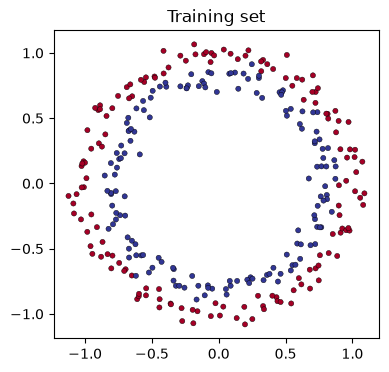

In [44]:
train_X, train_Y, test_X, test_Y = load_circles()
print("train_X", tuple(train_X.shape), "| train_Y", tuple(train_Y.shape), "| test_X", tuple(test_X.shape))
plt.figure(figsize=(4.2, 4))
plt.scatter(train_X[:, 0], train_X[:, 1], c=train_Y.flatten(), s=14, cmap=plt.cm.RdYlBu, edgecolors="k", linewidths=0.3)
plt.title("Training set"); plt.show()

### 1.2 The model, by hand
`model` trains the 3-layer network `[2, 10, 5, 1]` with batch gradient descent. The only thing that changes between experiments is the **initialization**: `"zeros"`, `"random"` or `"he"`. The three functions are defined just after.

In [45]:
def model(X, Y, initialization="he", lr=0.01, num_iters=15000, print_every=100):
    layer_dims = [X.shape[1], 10, 5, 1]
    if initialization == "zeros":
        params = initialize_parameters_zeros(layer_dims)
    elif initialization == "random":
        params = initialize_parameters_random(layer_dims)
    elif initialization == "he":
        params = initialize_parameters_he(layer_dims)
    costs = []
    for i in range(num_iters):
        A3, cache = forward_propagation(X, params)
        cost = compute_cost(A3, Y)
        grads = backward_propagation(X, Y, params, cache)
        params = update_parameters(params, grads, lr)
        if print_every and i % print_every == 0:
            costs.append(cost.item())
            if i % (5 * print_every) == 0:
                print(f"Cost after iteration {i}: {cost.item():.4f}")
    return params, costs

def show(params, costs, title):
    print(f"train accuracy {accuracy(logits_by_hand(params), train_X, train_Y):.1f}% | "
          f"test accuracy {accuracy(logits_by_hand(params), test_X, test_Y):.1f}%")
    plot_costs(costs, title, 1000)
    plt.figure(figsize=(4.2, 4)); plt.title(title)
    plot_decision_boundary(logits_by_hand(params), train_X, train_Y, lim=1.5); plt.show()

### 1.3 Zero initialization
All weights and biases start at 0. Shapes: $\mathbf{W}^{[l]}$ is $(n^{[l-1]}, n^{[l]})$ and $\mathbf{b}^{[l]}$ is $(1, n^{[l]})$.

In [46]:
def initialize_parameters_zeros(layer_dims):
    params = {}
    for l in range(1, len(layer_dims)):
        params[f"W{l}"] = torch.zeros(layer_dims[l - 1], layer_dims[l])
        params[f"b{l}"] = torch.zeros(1, layer_dims[l])
    return params

for k, v in initialize_parameters_zeros([3, 2, 1]).items():
    print(k, "=", v.tolist())

W1 = [[0.0, 0.0], [0.0, 0.0], [0.0, 0.0]]
b1 = [[0.0, 0.0]]
W2 = [[0.0], [0.0]]
b2 = [[0.0]]


In [47]:
params_zeros, costs_zeros = model(train_X, train_Y, initialization="zeros")

Cost after iteration 0: 0.6931
Cost after iteration 500: 0.6931
Cost after iteration 1000: 0.6931
Cost after iteration 1500: 0.6931
Cost after iteration 2000: 0.6931
Cost after iteration 2500: 0.6931
Cost after iteration 3000: 0.6931
Cost after iteration 3500: 0.6931
Cost after iteration 4000: 0.6931
Cost after iteration 4500: 0.6931
Cost after iteration 5000: 0.6931
Cost after iteration 5500: 0.6931
Cost after iteration 6000: 0.6931
Cost after iteration 6500: 0.6931
Cost after iteration 7000: 0.6931
Cost after iteration 7500: 0.6931
Cost after iteration 8000: 0.6931
Cost after iteration 8500: 0.6931
Cost after iteration 9000: 0.6931
Cost after iteration 9500: 0.6931
Cost after iteration 10000: 0.6931
Cost after iteration 10500: 0.6931
Cost after iteration 11000: 0.6931
Cost after iteration 11500: 0.6931
Cost after iteration 12000: 0.6931
Cost after iteration 12500: 0.6931
Cost after iteration 13000: 0.6931
Cost after iteration 13500: 0.6931
Cost after iteration 14000: 0.6931
Cost afte

train accuracy 50.0% | test accuracy 50.0%


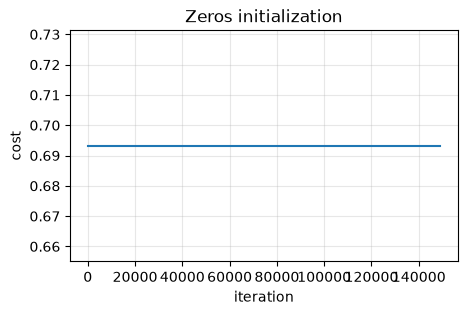

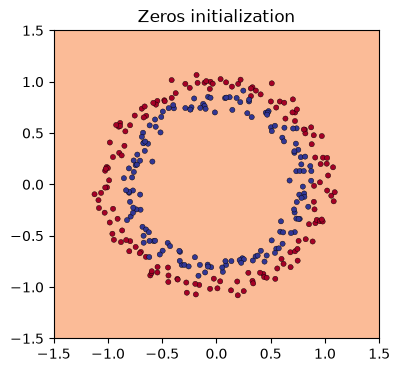

In [48]:
show(params_zeros, costs_zeros, "Zeros initialization")

The cost never moves from $\log 2 = 0.6931$, and the model predicts the same class for every point: 50% accuracy.

**Why?** With all weights 0, every $\mathbf{Z}^{[l]}$ is 0, every ReLU outputs 0, and the sigmoid outputs $\sigma(0) = 0.5$ for every example. The gradients of $\mathbf{W}^{[2]}$ and $\mathbf{W}^{[3]}$ are products with activations that are all 0, and the error sent back through $\mathbf{W}^{[3]} = \mathbf{0}$ is 0: only $b^{[3]}$ could move, and it stays at 0 because the two classes are balanced. More generally, units that start equal compute the same thing and get the same update forever: the network cannot **break the symmetry**.

**Remember:** initialize $\mathbf{W}^{[l]}$ randomly. The biases $\mathbf{b}^{[l]}$ can start at 0.

### 1.4 Large random initialization
Random weights break the symmetry. Here we try **large** ones: `torch.randn(...) * 10`.

In [49]:
def initialize_parameters_random(layer_dims, seed=3):
    torch.manual_seed(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        params[f"W{l}"] = torch.randn(layer_dims[l - 1], layer_dims[l]) * 10
        params[f"b{l}"] = torch.zeros(1, layer_dims[l])
    return params

In [50]:
params_random, costs_random = model(train_X, train_Y, initialization="random")

Cost after iteration 0: 7.1061
Cost after iteration 500: 0.4728
Cost after iteration 1000: 0.4190
Cost after iteration 1500: 0.3364
Cost after iteration 2000: 0.2978
Cost after iteration 2500: 0.3533
Cost after iteration 3000: 0.3691
Cost after iteration 3500: 0.3764
Cost after iteration 4000: 0.2738
Cost after iteration 4500: 0.2547
Cost after iteration 5000: 0.2600
Cost after iteration 5500: 0.2543
Cost after iteration 6000: 0.2489
Cost after iteration 6500: 0.2082
Cost after iteration 7000: 0.2890
Cost after iteration 7500: 0.2358
Cost after iteration 8000: 0.2314
Cost after iteration 8500: 0.2505
Cost after iteration 9000: 0.2234
Cost after iteration 9500: 0.2192
Cost after iteration 10000: 0.2162
Cost after iteration 10500: 0.2153
Cost after iteration 11000: 0.2112
Cost after iteration 11500: 0.2074
Cost after iteration 12000: 0.2257
Cost after iteration 12500: 0.2044
Cost after iteration 13000: 0.1941
Cost after iteration 13500: 0.1947
Cost after iteration 14000: 0.1900
Cost afte

train accuracy 93.7% | test accuracy 91.0%


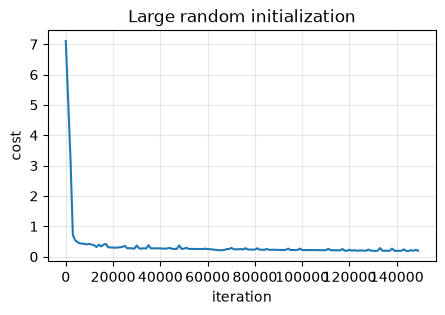

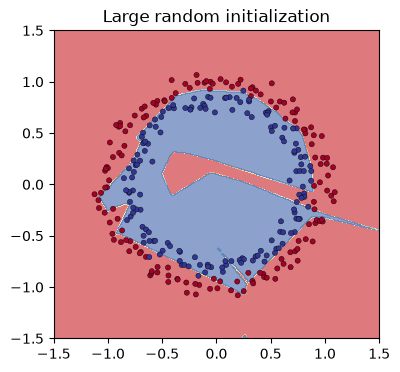

In [51]:
show(params_random, costs_random, "Large random initialization")

The symmetry is broken and the model learns something, but slowly:

- The **first cost is very large.** With weights of size 10, $\mathbf{Z}^{[3]}$ is huge, the sigmoid outputs almost exactly 0 or 1, and every wrong prediction costs $-\log(\text{almost } 0)$. (Without the `clamp` in `compute_cost`, the cost would be `inf`.)
- Saturated outputs and huge activations make the optimization slow and unstable: the activations are close to **exploding**.

### 1.5 He initialization
For ReLU layers, He et al. (2015) scale the random weights by $\sqrt{2 / n^{[l-1]}}$ (lecture: "Weight initialization for deep networks").

In [52]:
def initialize_parameters_he(layer_dims, seed=3):
    torch.manual_seed(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        params[f"W{l}"] = torch.randn(layer_dims[l - 1], layer_dims[l]) * (2 / layer_dims[l - 1]) ** 0.5
        params[f"b{l}"] = torch.zeros(1, layer_dims[l])
    return params

In [53]:
params_he, costs_he = model(train_X, train_Y, initialization="he")

Cost after iteration 0: 0.7258


Cost after iteration 500: 0.6867
Cost after iteration 1000: 0.6828
Cost after iteration 1500: 0.6795
Cost after iteration 2000: 0.6759
Cost after iteration 2500: 0.6707
Cost after iteration 3000: 0.6642
Cost after iteration 3500: 0.6563
Cost after iteration 4000: 0.6454
Cost after iteration 4500: 0.6322
Cost after iteration 5000: 0.6168
Cost after iteration 5500: 0.5978
Cost after iteration 6000: 0.5745
Cost after iteration 6500: 0.5488
Cost after iteration 7000: 0.5179
Cost after iteration 7500: 0.4846
Cost after iteration 8000: 0.4455
Cost after iteration 8500: 0.4060
Cost after iteration 9000: 0.3544
Cost after iteration 9500: 0.3080
Cost after iteration 10000: 0.2687
Cost after iteration 10500: 0.2371
Cost after iteration 11000: 0.2109
Cost after iteration 11500: 0.1892
Cost after iteration 12000: 0.1709
Cost after iteration 12500: 0.1558
Cost after iteration 13000: 0.1431
Cost after iteration 13500: 0.1327
Cost after iteration 14000: 0.1240
Cost after iteration 14500: 0.1166


train accuracy 97.7% | test accuracy 94.0%


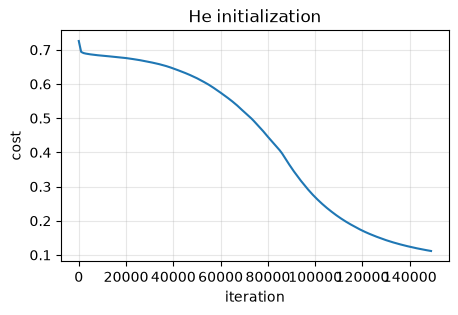

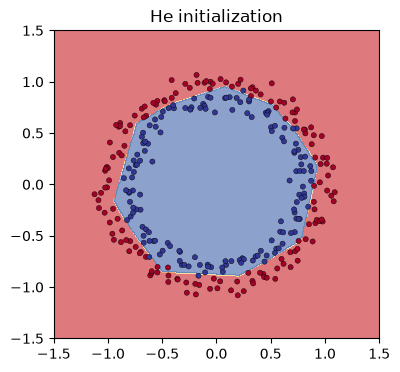

In [54]:
show(params_he, costs_he, "He initialization")

### 1.6 Using PyTorch

| By hand | `torch.nn` |
|---|---|
| `torch.zeros(n_prev, n_l)` | `nn.init.zeros_(layer.weight)` |
| `torch.randn(n_prev, n_l) * 10` | `nn.init.normal_(layer.weight, mean=0.0, std=10.0)` |
| `torch.randn(n_prev, n_l) * (2 / n_prev) ** 0.5` | `nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")` |
| `torch.zeros(1, n_l)` | `nn.init.zeros_(layer.bias)` |

**One difference to remember:** `nn.Linear` stores its weight as `(n_out, n_in)`, the transpose of our $\mathbf{W}^{[l]}$, and computes `X @ weight.T + bias`. "Kaiming" is He's first name; by default it uses `n_in` (the "fan-in"), as in the lecture.

In [55]:
class CircleModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=2, out_features=10)
        self.layer_2 = nn.Linear(in_features=10, out_features=5)
        self.layer_3 = nn.Linear(in_features=5, out_features=1)
        self.relu = nn.ReLU()

    def forward(self, x):
        # LINEAR -> RELU -> LINEAR -> RELU -> LINEAR (logits)
        return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))

def init_weights(model, method, seed=3):
    torch.manual_seed(seed)
    for layer in model.modules():
        if isinstance(layer, nn.Linear):
            if method == "zeros":
                nn.init.zeros_(layer.weight)
            elif method == "random":
                nn.init.normal_(layer.weight, mean=0.0, std=10.0)
            elif method == "he":
                nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
            nn.init.zeros_(layer.bias)
    return model

model_0 = init_weights(CircleModel(), "he").to(device)
print(model_0)
print("layer_1.weight:", tuple(model_0.layer_1.weight.shape), "= (n_out, n_in) | std",
      round(model_0.layer_1.weight.std().item(), 3), "| sqrt(2 / n_in) =", round((2 / 2) ** 0.5, 3))

CircleModel(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=5, bias=True)
  (layer_3): Linear(in_features=5, out_features=1, bias=True)
  (relu): ReLU()
)
layer_1.weight: (10, 2) = (n_out, n_in) | std 0.676 | sqrt(2 / n_in) = 1.0


In [56]:
check_model = CircleModel()
p = initialize_parameters_he([2, 10, 5, 1])
with torch.no_grad():
    for l, layer in zip([1, 2, 3], [check_model.layer_1, check_model.layer_2, check_model.layer_3]):
        layer.weight.copy_(p[f"W{l}"].T)          # (n_in, n_out) -> (n_out, n_in)
        layer.bias.copy_(p[f"b{l}"].flatten())

A3_hand, cache = forward_propagation(train_X, p)
grads = backward_propagation(train_X, train_Y, p, cache)
loss = nn.BCEWithLogitsLoss()(check_model(train_X), train_Y)
loss.backward()                                    # autograd

print(f"sigmoid(logits) vs A3: max difference {(torch.sigmoid(check_model(train_X)) - A3_hand).abs().max().item():.1e}")
for l, layer in zip([1, 2, 3], [check_model.layer_1, check_model.layer_2, check_model.layer_3]):
    print(f"dW{l}: max difference {(layer.weight.grad.T - grads[f'dW{l}']).abs().max().item():.1e} | "
          f"db{l}: max difference {(layer.bias.grad - grads[f'db{l}'].flatten()).abs().max().item():.1e}")

sigmoid(logits) vs A3: max difference 1.2e-07
dW1: max difference 5.6e-09 | db1: max difference 1.9e-09
dW2: max difference 3.0e-08 | db2: max difference 1.9e-09
dW3: max difference 1.5e-08 | db3: max difference 7.5e-09


In [57]:
def train_and_test(model, loss_fn, optimizer, X_train, y_train, X_test, y_test, epochs, print_every=None):
    X_train, y_train = X_train.to(device), y_train.to(device)
    X_test, y_test = X_test.to(device), y_test.to(device)
    for epoch in range(epochs):
        ### Training
        model.train()
        y_logits = model(X_train)                       # 1. forward pass (logits)
        y_pred = torch.round(torch.sigmoid(y_logits))   #    logits -> probabilities -> labels
        loss = loss_fn(y_logits, y_train)               # 2. loss
        acc = accuracy_fn(y_true=y_train, y_pred=y_pred)
        optimizer.zero_grad()                           # 3. zero the gradients
        loss.backward()                                 # 4. backpropagation
        optimizer.step()                                # 5. gradient descent step

        ### Testing
        model.eval()
        with torch.inference_mode():
            test_logits = model(X_test)
            test_pred = torch.round(torch.sigmoid(test_logits))
            test_loss = loss_fn(test_logits, y_test)
            test_acc = accuracy_fn(y_true=y_test, y_pred=test_pred)

        if print_every and epoch % print_every == 0:
            print(f"Epoch: {epoch:5d} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%")
    return model

In [58]:
torch.manual_seed(42)
model_0 = init_weights(CircleModel(), "he").to(device)
loss_fn = nn.BCEWithLogitsLoss()                                 # sigmoid + binary cross-entropy
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.01)
model_0 = train_and_test(model_0, loss_fn, optimizer, train_X, train_Y, test_X, test_Y, epochs=15000, print_every=3000)

Epoch:     0 | Loss: 0.69057, Accuracy: 50.00% | Test loss: 0.69148, Test acc: 50.00%
Epoch:  3000 | Loss: 0.63031, Accuracy: 64.33% | Test loss: 0.63650, Test acc: 63.00%
Epoch:  6000 | Loss: 0.41412, Accuracy: 93.33% | Test loss: 0.42873, Test acc: 94.00%
Epoch:  9000 | Loss: 0.18768, Accuracy: 97.33% | Test loss: 0.22124, Test acc: 94.00%
Epoch: 12000 | Loss: 0.11551, Accuracy: 98.33% | Test loss: 0.16742, Test acc: 93.00%


initialization      train     test
zeros               50.0%    50.0%
random              79.0%    76.0%
he                  98.7%    93.0%
default             97.3%    92.0%


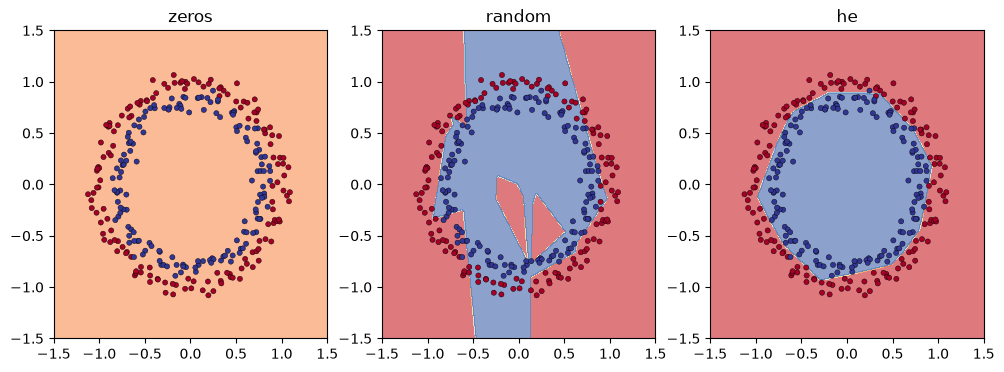

In [59]:
results_init = {}
for method in ["zeros", "random", "he", "default"]:
    torch.manual_seed(3)
    m = CircleModel()                          # PyTorch's default initialization
    if method != "default":
        init_weights(m, method)
    m = m.to(device)
    opt = torch.optim.SGD(m.parameters(), lr=0.01)
    train_and_test(m, nn.BCEWithLogitsLoss(), opt, train_X, train_Y, test_X, test_Y, epochs=15000)
    results_init[method] = (accuracy(m, train_X, train_Y), accuracy(m, test_X, test_Y))

print(f"{'initialization':16s} {'train':>8s} {'test':>8s}")
for method, (tr, te) in results_init.items():
    print(f"{method:16s} {tr:7.1f}% {te:7.1f}%")

plt.figure(figsize=(12, 4))
for k, method in enumerate(["zeros", "random", "he"]):
    torch.manual_seed(3)
    m = init_weights(CircleModel(), method).to(device)
    train_and_test(m, nn.BCEWithLogitsLoss(), torch.optim.SGD(m.parameters(), lr=0.01), train_X, train_Y, test_X, test_Y, epochs=15000)
    plt.subplot(1, 3, k + 1); plt.title(method); plot_decision_boundary(m, train_X, train_Y, lim=1.5)
plt.show()

**What to remember from Part 1**
- Different initializations give very different results with the same network and the same training.
- Random weights break the symmetry; weights that are too large saturate the output and slow down learning.
- For ReLU networks, use He initialization: `nn.init.kaiming_normal_(w, nonlinearity="relu")`.

---
## 2 · Regularization

### 2.1 The data
A noisy 2-D dataset: 211 training points and 200 test points. The true boundary is a gentle curve, but the training labels contain mistakes: about 6% random errors, plus a few small **pockets** of wrong labels (for example, a region labeled by a careless annotator). The test labels contain only the random errors. A network that fits the pockets will generalize badly.

In [60]:
def make_noisy_2d(m, seed, pockets=()):
    rng = np.random.default_rng(seed)
    X = rng.uniform(-1, 1, (m, 2))                                  # uniform in [-1, 1]^2
    Y = (X[:, 1] > 0.35 * np.sin(2.2 * X[:, 0]) - 0.1 * X[:, 0]).astype(float)
    flip = rng.random(m) < 0.06                                     # random label errors
    for cx, cy, r in pockets:                                       # pockets of wrong labels
        inside = (X[:, 0] - cx) ** 2 + (X[:, 1] - cy) ** 2 < r ** 2
        flip |= inside & (rng.random(m) < 0.7)
    Y[flip] = 1 - Y[flip]
    return torch.tensor(X, dtype=torch.float32), torch.tensor(Y, dtype=torch.float32).reshape(-1, 1)

train (211, 2) | test (200, 2) | fraction of class 1: 0.5


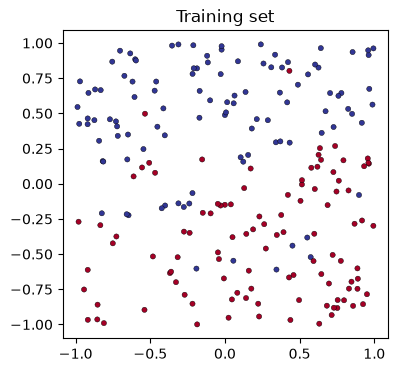

In [61]:
POCKETS = [(-0.55, 0.05, 0.12), (0.1, 0.45, 0.10), (0.5, -0.45, 0.12), (-0.2, -0.55, 0.10)]
reg_train_X, reg_train_Y = make_noisy_2d(211, seed=0, pockets=POCKETS)
reg_test_X, reg_test_Y = make_noisy_2d(200, seed=1)
print("train", tuple(reg_train_X.shape), "| test", tuple(reg_test_X.shape), "| fraction of class 1:", round(reg_train_Y.mean().item(), 2))
plt.figure(figsize=(4.2, 4))
plt.scatter(reg_train_X[:, 0], reg_train_X[:, 1], c=reg_train_Y.flatten(), s=14, cmap=plt.cm.RdYlBu, edgecolors="k", linewidths=0.3)
plt.title("Training set"); plt.show()

### 2.2 The baseline model, by hand
The network is `[2, 20, 3, 1]`, initialized with $\sqrt{1/n^{[l-1]}}$ and trained for 30,000 iterations with $\alpha = 0.3$. `model_reg` can run in three modes:
- no regularization: `lambd = 0`, `keep_prob = 1`;
- **L2 regularization**: `lambd > 0` (we write `lambd` because `lambda` is a Python keyword);
- **dropout**: `keep_prob < 1`.

The L2 and dropout functions it calls are written in 2.3 and 2.4.

Cost after iteration 0: 0.7019
Cost after iteration 10000: 0.1246
Cost after iteration 20000: 0.0574
no regularization: train accuracy 97.6% | test accuracy 88.5%


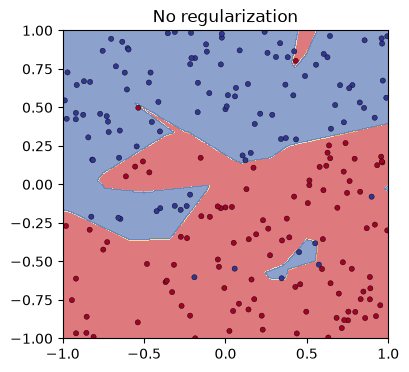

In [62]:
def initialize_parameters(layer_dims, seed=3):
    torch.manual_seed(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        params[f"W{l}"] = torch.randn(layer_dims[l - 1], layer_dims[l]) / layer_dims[l - 1] ** 0.5
        params[f"b{l}"] = torch.zeros(1, layer_dims[l])
    return params

def model_reg(X, Y, lr=0.3, num_iters=30000, lambd=0.0, keep_prob=1.0, print_every=10000, seed=1):
    params = initialize_parameters([X.shape[1], 20, 3, 1])
    gen = torch.Generator().manual_seed(seed)          # random masks for dropout
    for i in range(num_iters):
        if keep_prob == 1:
            A3, cache = forward_propagation(X, params)
        else:
            A3, cache = forward_propagation_with_dropout(X, params, keep_prob, gen)
        if lambd == 0:
            cost = compute_cost(A3, Y)
        else:
            cost = compute_cost_with_regularization(A3, Y, params, lambd)
        if lambd == 0 and keep_prob == 1:
            grads = backward_propagation(X, Y, params, cache)
        elif lambd != 0:
            grads = backward_propagation_with_regularization(X, Y, params, cache, lambd)
        else:
            grads = backward_propagation_with_dropout(X, Y, params, cache, keep_prob)
        params = update_parameters(params, grads, lr)
        if print_every and i % print_every == 0:
            print(f"Cost after iteration {i}: {cost.item():.4f}")
    return params

def report(name, model):
    tr = accuracy(model, reg_train_X, reg_train_Y)
    te = accuracy(model, reg_test_X, reg_test_Y)
    print(f"{name}: train accuracy {tr:.1f}% | test accuracy {te:.1f}%")
    return tr, te

def plot_reg(model, title):
    plt.figure(figsize=(4.2, 4)); plt.title(title)
    plot_decision_boundary(model, reg_train_X, reg_train_Y, lim=1.0); plt.show()

results_reg = {}
params_base = model_reg(reg_train_X, reg_train_Y)
results_reg["no regularization"] = report("no regularization", logits_by_hand(params_base))
plot_reg(logits_by_hand(params_base), "No regularization")

This is the **baseline**. Compare the training and the test accuracy, and look at the boundary: it bends around the pockets of wrong labels. The model is **overfitting** (high variance).

### 2.3 L2 regularization, by hand
The cost gets a penalty on the size of the weights (lecture: "L2 regularization: neural network"):
$$J_{\text{regularized}} = \underbrace{-\frac{1}{m}\sum_{i=1}^{m}\Big(y^{(i)}\log a^{[3](i)} + (1-y^{(i)})\log\big(1-a^{[3](i)}\big)\Big)}_{\text{cross-entropy cost}} + \underbrace{\frac{\lambda}{2m}\sum_{l=1}^{3}\lVert\mathbf{W}^{[l]}\rVert_F^2}_{\text{L2 cost}}$$
and, because the cost changed, every weight gradient gets an extra term: $d\mathbf{W}^{[l]} = (\text{from backprop}) + \frac{\lambda}{m}\mathbf{W}^{[l]}$. The biases are not regularized.

Cost after iteration 0: 0.7342
Cost after iteration 10000: 0.2881
Cost after iteration 20000: 0.2880
L2, lambda = 0.7: train accuracy 93.4% | test accuracy 95.5%


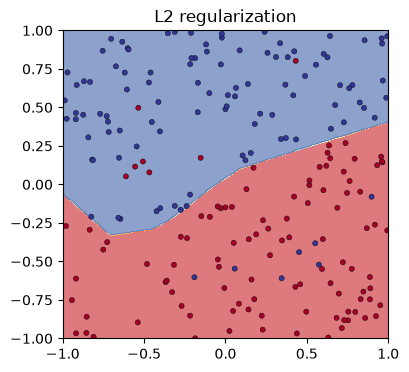

In [63]:
def compute_cost_with_regularization(A3, Y, params, lambd):
    m = Y.shape[0]
    cross_entropy_cost = compute_cost(A3, Y)
    L2_cost = lambd / (2 * m) * sum((params[f"W{l}"] ** 2).sum() for l in [1, 2, 3])
    return cross_entropy_cost + L2_cost

def backward_propagation_with_regularization(X, Y, params, cache, lambd):
    m = X.shape[0]
    grads = backward_propagation(X, Y, params, cache)     # the usual gradients
    for l in [1, 2, 3]:
        grads[f"dW{l}"] = grads[f"dW{l}"] + lambd / m * params[f"W{l}"]
    return grads

params_L2 = model_reg(reg_train_X, reg_train_Y, lambd=0.7)
results_reg["L2, lambda = 0.7"] = report("L2, lambda = 0.7", logits_by_hand(params_L2))
plot_reg(logits_by_hand(params_L2), "L2 regularization")

Compare with the baseline: the training accuracy should go **down** and the test accuracy **up**, and the boundary should no longer bend around the pockets. Smaller weights give a simpler, smoother function.

`backward_propagation_with_regularization` reuses `backward_propagation` and only adds $\frac{\lambda}{m}\mathbf{W}^{[l]}$: the regularization changes nothing else.

### 2.4 Dropout, by hand
Inverted dropout on the two hidden layers (lecture: "Dropout regularization"). For layer 1, at **every** iteration:
1. draw a mask `D1` of the same shape as `A1`, $(m, n^{[1]})$, with 1 with probability `keep_prob` and 0 otherwise;
2. `A1 = A1 * D1`: shut down the dropped units;
3. `A1 = A1 / keep_prob`: keep the expected value of `A1` unchanged.

In the backward pass, apply the **same** mask and the same scaling to `dA1`. Same for layer 2. No dropout on the input or the output layer.

Cost after iteration 0: 0.7146
Cost after iteration 10000: 0.2042
Cost after iteration 20000: 0.1942
dropout, keep_prob = 0.86: train accuracy 95.3% | test accuracy 94.0%


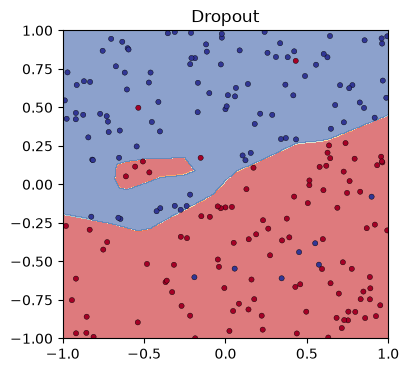

In [64]:
def forward_propagation_with_dropout(X, params, keep_prob, gen):
    Z1 = X @ params["W1"] + params["b1"]
    A1 = torch.relu(Z1)
    D1 = (torch.rand(A1.shape, generator=gen) < keep_prob).float()    # step 1
    A1 = A1 * D1                                                      # step 2
    A1 = A1 / keep_prob                                               # step 3
    Z2 = A1 @ params["W2"] + params["b2"]
    A2 = torch.relu(Z2)
    D2 = (torch.rand(A2.shape, generator=gen) < keep_prob).float()
    A2 = A2 * D2 / keep_prob
    Z3 = A2 @ params["W3"] + params["b3"]
    A3 = torch.sigmoid(Z3)
    cache = (Z1, D1, A1, Z2, D2, A2, Z3, A3)
    return A3, cache

def backward_propagation_with_dropout(X, Y, params, cache, keep_prob):
    m = X.shape[0]
    Z1, D1, A1, Z2, D2, A2, Z3, A3 = cache
    dZ3 = A3 - Y
    dW3 = A2.T @ dZ3 / m
    db3 = dZ3.sum(dim=0, keepdim=True) / m
    dA2 = dZ3 @ params["W3"].T
    dA2 = dA2 * D2 / keep_prob                 # same mask, same scaling
    dZ2 = dA2 * (Z2 > 0).float()
    dW2 = A1.T @ dZ2 / m
    db2 = dZ2.sum(dim=0, keepdim=True) / m
    dA1 = dZ2 @ params["W2"].T
    dA1 = dA1 * D1 / keep_prob
    dZ1 = dA1 * (Z1 > 0).float()
    dW1 = X.T @ dZ1 / m
    db1 = dZ1.sum(dim=0, keepdim=True) / m
    return {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2, "dW3": dW3, "db3": db3}

params_drop = model_reg(reg_train_X, reg_train_Y, keep_prob=0.86)
results_reg["dropout, keep_prob = 0.86"] = report("dropout, keep_prob = 0.86", logits_by_hand(params_drop))
plot_reg(logits_by_hand(params_drop), "Dropout")

### 2.5 Using PyTorch
| By hand | PyTorch |
|---|---|
| `compute_cost_with_regularization` and $+\frac{\lambda}{m}\mathbf{W}^{[l]}$ in backprop | `weight_decay=λ/m` in the optimizer |
| masks `D1`, `D2`, divide by `keep_prob` | `nn.Dropout(p=1 - keep_prob)` after each hidden ReLU |
| no dropout at test time | `model.eval()` (and `model.train()` to go back) |

Two details:
- **`p` in `nn.Dropout` is the probability of *dropping* a unit**, so `p = 1 - keep_prob`.
- `weight_decay` applies to every parameter it is given. To regularize only the weights, as in the lecture, give the optimizer two **parameter groups**.

In [65]:
class RegModel(nn.Module):
    def __init__(self, keep_prob=1.0):
        super().__init__()
        self.layer_1 = nn.Linear(2, 20)
        self.layer_2 = nn.Linear(20, 3)
        self.layer_3 = nn.Linear(3, 1)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=1 - keep_prob)      # p = probability of DROPPING a unit

    def forward(self, x):
        x = self.dropout(self.relu(self.layer_1(x)))
        x = self.dropout(self.relu(self.layer_2(x)))
        return self.layer_3(x)                          # logits

def make_optimizer(model, lr, lambd, m):
    weights = [p for name, p in model.named_parameters() if name.endswith("weight")]
    biases = [p for name, p in model.named_parameters() if name.endswith("bias")]
    return torch.optim.SGD([{"params": weights, "weight_decay": lambd / m},
                            {"params": biases, "weight_decay": 0.0}], lr=lr)

print(RegModel(keep_prob=0.86))

RegModel(
  (layer_1): Linear(in_features=2, out_features=20, bias=True)
  (layer_2): Linear(in_features=20, out_features=3, bias=True)
  (layer_3): Linear(in_features=3, out_features=1, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.14, inplace=False)
)


**Check 1: `weight_decay` does exactly what our L2 code does.** One step with `weight_decay=λ/m` versus one step with the penalty written in the cost:

In [66]:
lambd, m = 0.7, reg_train_X.shape[0]
torch.manual_seed(0); model_a = RegModel()
torch.manual_seed(0); model_b = RegModel()

# (a) weight_decay in the optimizer
opt_a = make_optimizer(model_a, lr=0.3, lambd=lambd, m=m)
loss_a = nn.BCEWithLogitsLoss()(model_a(reg_train_X), reg_train_Y)
opt_a.zero_grad(); loss_a.backward(); opt_a.step()

# (b) the L2 penalty written in the cost, plain SGD
opt_b = torch.optim.SGD(model_b.parameters(), lr=0.3)
penalty = lambd / (2 * m) * sum((layer.weight ** 2).sum() for layer in [model_b.layer_1, model_b.layer_2, model_b.layer_3])
loss_b = nn.BCEWithLogitsLoss()(model_b(reg_train_X), reg_train_Y) + penalty
opt_b.zero_grad(); loss_b.backward(); opt_b.step()

diff = max((pa - pb).abs().max().item() for pa, pb in zip(model_a.parameters(), model_b.parameters()))
print(f"max difference between the parameters after one step: {diff:.1e}")

max difference between the parameters after one step: 0.0e+00


Identical up to rounding. Note that `loss_a` does **not** contain the penalty: with `weight_decay`, the regularization lives in the update rule, not in the printed loss.

**Check 2: `nn.Dropout` is inverted dropout.** On a tensor of ones, in training mode and in evaluation mode:

In [67]:
torch.manual_seed(0)
drop = nn.Dropout(p=0.5)
drop.train()
print("train mode:", drop(torch.ones(10)))
drop.eval()
print("eval mode: ", drop(torch.ones(10)))

train mode: tensor([0., 0., 2., 0., 0., 0., 2., 2., 0., 2.])
eval mode:  tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


In training mode, about half of the values are set to 0 and the others are divided by `keep_prob = 0.5`, i.e. multiplied by 2. In evaluation mode, `nn.Dropout` does nothing. This is why the loop calls `model.train()` before the training step and `model.eval()` before testing.

Finally, the three models of this part, trained with the same loop as in Part 1:

PyTorch | no regularization: train accuracy 96.7% | test accuracy 91.0%
PyTorch | L2, lambda = 0.7: train accuracy 91.9% | test accuracy 94.0%
PyTorch | dropout, keep_prob = 0.86: train accuracy 97.2% | test accuracy 87.5%


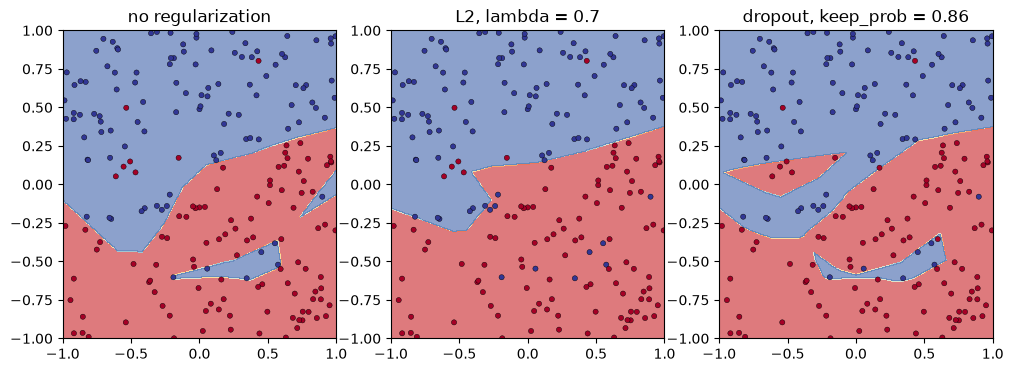

In [68]:
def train_reg_model(lambd=0.0, keep_prob=1.0, lr=0.3, epochs=30000, seed=3, print_every=None):
    torch.manual_seed(seed)
    model = RegModel(keep_prob).to(device)
    optimizer = make_optimizer(model, lr, lambd, reg_train_X.shape[0])
    return train_and_test(model, nn.BCEWithLogitsLoss(), optimizer, reg_train_X, reg_train_Y,
                          reg_test_X, reg_test_Y, epochs=epochs, print_every=print_every)

results_nn = {}
models_nn = {}
for name, kw in [("no regularization", {}), ("L2, lambda = 0.7", {"lambd": 0.7}), ("dropout, keep_prob = 0.86", {"keep_prob": 0.86})]:
    models_nn[name] = train_reg_model(**kw)
    results_nn[name] = report(f"PyTorch | {name}", models_nn[name])

plt.figure(figsize=(12, 4))
for k, name in enumerate(models_nn):
    plt.subplot(1, 3, k + 1); plt.title(name); plot_decision_boundary(models_nn[name], reg_train_X, reg_train_Y, lim=1.0)
plt.show()

The numbers are not identical to the hand-written version (`nn.Linear` draws its random numbers differently, and the dropout masks differ), but they should lead to the same conclusions.

### 2.6 Conclusions

In [69]:
print(f"{'model':28s} {'by hand':>18s} {'PyTorch':>18s}")
print(f"{'':28s} {'train':>8s} {'test':>8s}   {'train':>8s} {'test':>8s}")
for name in results_reg:
    (a, b), (c, d) = results_reg[name], results_nn[name]
    print(f"{name:28s} {a:7.1f}% {b:7.1f}%   {c:7.1f}% {d:7.1f}%")

model                                   by hand            PyTorch
                                train     test      train     test
no regularization               97.6%    88.5%      96.7%    91.0%
L2, lambda = 0.7                93.4%    95.5%      91.9%    94.0%
dropout, keep_prob = 0.86       95.3%    94.0%      97.2%    87.5%


**What to remember from Part 2**
- Regularization **lowers the training accuracy** and **raises the test accuracy**: it stops the network from fitting the noise.
- L2 adds $\frac{\lambda}{2m}\sum_l\lVert\mathbf{W}^{[l]}\rVert_F^2$ to the cost and $\frac{\lambda}{m}\mathbf{W}^{[l]}$ to each gradient; in PyTorch, `weight_decay=λ/m`.
- Dropout is used **only during training**, in the forward **and** the backward pass, with the division by `keep_prob`; in PyTorch, `nn.Dropout(p=1 - keep_prob)` with `model.train()` / `model.eval()`.
- $\lambda$ and `keep_prob` are hyperparameters, chosen on a dev set.

---
## ★ Assignment (to submit)

### Exercise 1 · The moons dataset
Make a binary classification dataset with scikit-learn's `make_moons()`: 1000 samples, `noise=0.07`, `random_state=42`. Turn it into PyTorch tensors (`float32`; labels of shape $(m, 1)$) and split it into 80% training and 20% test data with `train_test_split(..., test_size=0.2, random_state=42)`. Plot the training set.

X_train Shape:  torch.Size([800, 2])
X_test Shape:  torch.Size([200, 2])
y_train Shape:  torch.Size([800, 1])
y_test Shape:  torch.Size([200, 1])


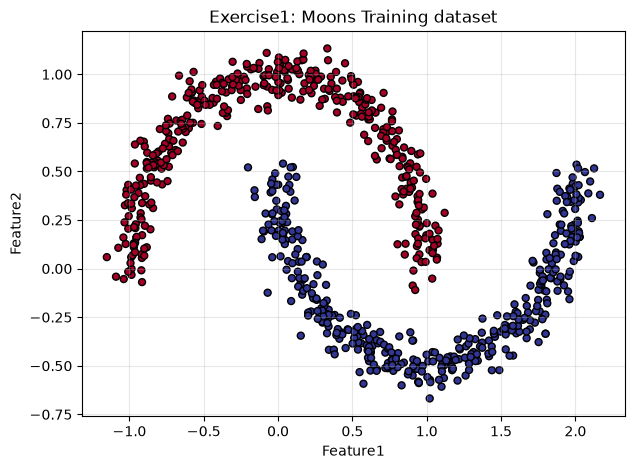

In [70]:
# Exercise 1

X, y = make_moons(
    n_samples = 1000,
    noise = 0.07,
    random_state = 42
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

X_train = torch.tensor(X_train, dtype = torch.float32)
X_test = torch.tensor(X_test, dtype = torch.float32)
y_train = torch.tensor(y_train, dtype = torch.float32).reshape(-1, 1)
y_test = torch.tensor(y_test, dtype = torch.float32).reshape(-1, 1)

print("X_train Shape: " ,X_train.shape)
print("X_test Shape: " ,X_test.shape)
print("y_train Shape: " ,y_train.shape)
print("y_test Shape: " ,y_test.shape)


#Plot training data

plt.figure(figsize=(7, 5))

plt.scatter(
    X_train[:, 0],
    X_train[:, 1],
    c = y_train.flatten(),
    cmap = plt.cm.RdYlBu,
    edgecolors = "black",
    s = 25
)
plt.title("Exercise1: Moons Training dataset")
plt.xlabel("Feature1")
plt.ylabel("Feature2")
plt.grid(alpha = 0.3)
plt.show()

The `make_moons` function generated 1,000 points arranged in two crescent shapes. The setting `noise=0.07` adds a small amount of scatter around each curve. Both dataset generation and the 80/20 split used `random_state=42` for reproducibility.

The features and labels were converted to `float32` tensors. The training set contains 800 points with feature shape `(800, 2)` and label shape `(800, 1)`. The test set contains 200 points with corresponding shapes `(200, 2)` and `(200, 1)`. The scatter plot uses a different color for each training class.

### Exercise 2 · A model for the moons
Build a model by subclassing `nn.Module`, with non-linear activation functions, capable of fitting the moons. It should output **one logit**. Initialize every `nn.Linear` with **He initialization** and zero biases (Part 1.6). Print the model and its number of parameters.

In [71]:
# Exercise 2
class MoonModel(nn.Module):
  def __init__(self):
    super().__init__()

    self.layer1 = nn.Linear(
        in_features = 2,
        out_features = 16
    )

    self.layer2 = nn.Linear(
        in_features = 16,
        out_features = 16
    )

    self.layer3 = nn.Linear(
        in_features = 16,
        out_features = 1
    )

    self.relu = nn.ReLU()

    # He initialization for ReLU layer
    self.initialize_weights()

  def initialize_weights(self):
    for layer in [
        self.layer1,
        self.layer2,
        self.layer3
    ]:
        nn.init.kaiming_normal_(layer.weight,
                                nonlinearity = "relu")

        #Bias start from zeros
        nn.init.zeros_(layer.bias)

  def forward(self, x):
    x = self.layer1(x)
    x = self.relu(x)

    x = self.layer2(x)
    x = self.relu(x)

    x = self.layer3(x)

    return x

#Create the model
model = MoonModel().to(device)

#Count trainable parameters
number_of_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(model)
print("Number of trainable parameters: ", number_of_parameters)

MoonModel(
  (layer1): Linear(in_features=2, out_features=16, bias=True)
  (layer2): Linear(in_features=16, out_features=16, bias=True)
  (layer3): Linear(in_features=16, out_features=1, bias=True)
  (relu): ReLU()
)
Number of trainable parameters:  337


`MoonModel` uses a `2 → 16 → 16 → 1` architecture. It takes two coordinates as input, passes them through two hidden layers with 16 units each, and produces one logit per point. ReLU activation in the hidden layers allows the model to learn a nonlinear decision boundary.

All three linear layers use He initialization for their weights and zero initialization for their biases. The model has 337 trainable parameters.

### Exercise 3 · Loss and optimizer
Set up a loss function for binary classification that works with **logits**, and an SGD optimizer (batch gradient descent). Explain in one sentence why `nn.BCEWithLogitsLoss` is preferred to `nn.Sigmoid()` + `nn.BCELoss()`.

In [72]:
# Exercise 3

# Loss function for Binary classification
loss_fn = nn.BCEWithLogitsLoss()

# SGD optimizer for batch gradient descent
optimizer = torch.optim.SGD(
    model.parameters(),
    lr = 0.1
)

print("Loss Function: ", loss_fn)
print("Optimizer: ", optimizer)

# Explanation:

# BCEWithLogitsLoss is preferred because it combines Sigmoid
# and Binary Cross-Entropy in one numerically stable function.

Loss Function:  BCEWithLogitsLoss()
Optimizer:  SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.1
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)




`BCEWithLogitsLoss` is appropriate for the Moons dataset because the task has two classes and `MoonModel` outputs one raw logit per point. It combines sigmoid and binary cross-entropy in a single, numerically stable calculation.

SGD was configured with a learning rate of `0.1`. During training, the optimizer uses the gradients to update the model’s weights and biases. The learning rate controls the size of each update.

### Exercise 4 · Training and testing loop
Write a training and testing loop (you may reuse `train_and_test` or write your own) and train the model until it reaches **more than 96% test accuracy**. Print the training and test loss and accuracy every 100 epochs. If you do not reach 96%, change the learning rate, the number of epochs or the number of hidden units, and explain what you changed.

In [73]:
# Exercise 4
def train_and_test(model, loss_fn, optimizer, epochs=2000, print_every=100):
    history = []

    # Move the data to the same device as the model
    X_tr, y_tr = X_train.to(device), y_train.to(device)
    X_te, y_te = X_test.to(device), y_test.to(device)

    for epoch in range(1, epochs + 1):
        # Training
        model.train()
        train_logits = model(X_tr)
        train_loss = loss_fn(train_logits, y_tr)
        train_pred = torch.round(torch.sigmoid(train_logits))
        train_acc = accuracy_fn(y_tr, train_pred)

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        # Testing
        model.eval()
        with torch.inference_mode():
            test_logits = model(X_te)
            test_loss = loss_fn(test_logits, y_te)
            test_pred = torch.round(torch.sigmoid(test_logits))
            test_acc = accuracy_fn(y_te, test_pred)

        history.append((train_loss.item(), train_acc, test_loss.item(), test_acc))

        if epoch % print_every == 0 or epoch == epochs:
            print(
                f"Epoch: {epoch:4d} | "
                f"Train Loss: {train_loss.item():.5f}, Train Accuracy: {train_acc:.2f}% | "
                f"Test Loss: {test_loss.item():.5f}, Test Accuracy: {test_acc:.2f}%"
            )

    return history


# Start fresh each time this cell runs
torch.manual_seed(42)
model = MoonModel().to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

history_model = train_and_test(
    model, loss_fn, optimizer, epochs=10000, print_every=100
)

final_test_acc = history_model[-1][3]
print(f"Final Test Accuracy: {final_test_acc:.2f}%")

Epoch:  100 | Train Loss: 0.24794, Train Accuracy: 87.62% | Test Loss: 0.24977, Test Accuracy: 86.50%
Epoch:  200 | Train Loss: 0.18951, Train Accuracy: 91.88% | Test Loss: 0.18828, Test Accuracy: 91.00%
Epoch:  300 | Train Loss: 0.13928, Train Accuracy: 94.00% | Test Loss: 0.13305, Test Accuracy: 94.00%
Epoch:  400 | Train Loss: 0.09015, Train Accuracy: 97.38% | Test Loss: 0.08039, Test Accuracy: 98.00%
Epoch:  500 | Train Loss: 0.05733, Train Accuracy: 98.88% | Test Loss: 0.04781, Test Accuracy: 99.50%
Epoch:  600 | Train Loss: 0.03852, Train Accuracy: 99.38% | Test Loss: 0.03177, Test Accuracy: 99.50%
Epoch:  700 | Train Loss: 0.02777, Train Accuracy: 99.88% | Test Loss: 0.02230, Test Accuracy: 100.00%
Epoch:  800 | Train Loss: 0.02105, Train Accuracy: 100.00% | Test Loss: 0.01653, Test Accuracy: 100.00%
Epoch:  900 | Train Loss: 0.01665, Train Accuracy: 100.00% | Test Loss: 0.01266, Test Accuracy: 100.00%
Epoch: 1000 | Train Loss: 0.01361, Train Accuracy: 100.00% | Test Loss: 0.010


A freshly initialized `MoonModel` was trained for 10,000 epochs. Each epoch used all 800 training points to compute the gradients and update the parameters once. Training and test loss and accuracy were recorded in the output every 100 epochs.

The first reported result above the required 96% threshold was 98% test accuracy at epoch 400. Test accuracy reached 100% at epoch 700 and remained at 100% at every reported checkpoint through epoch 10,000.


### Exercise 5 · Decision boundaries
Plot the decision boundary of your trained model on the training set and on the test set, side by side, with `plot_decision_boundary`.

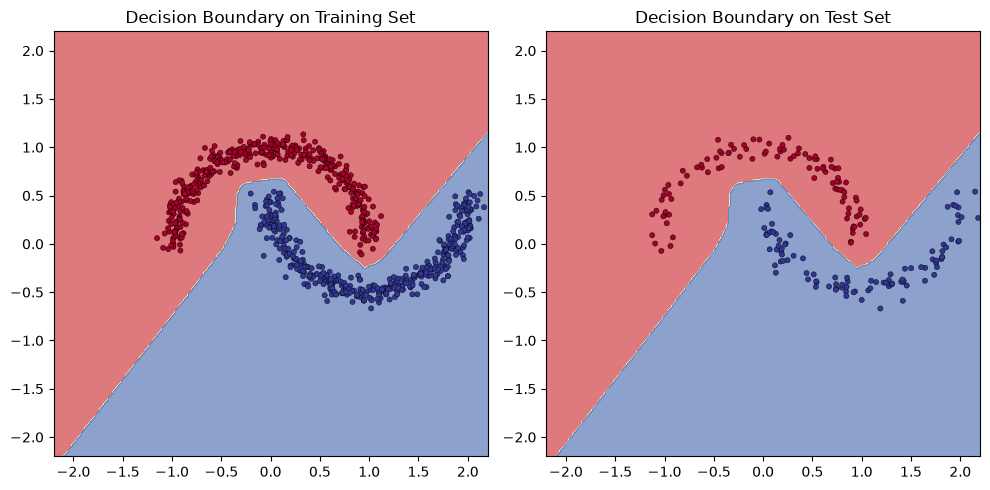

In [74]:
# Exercise 5
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plot_decision_boundary(model, X_train, y_train, lim = 2.2)
plt.title("Decision Boundary on Training Set")
plt.subplot(1, 2, 2)
plot_decision_boundary(model, X_test, y_test, lim = 2.2)
plt.title("Decision Boundary on Test Set")
plt.tight_layout()
plt.show()


The training and test plots show the decision boundary of the same trained model. The background color indicates the predicted class at each location, while the color of each data point indicates its true class. A disagreement between the two indicates a classification error.

Both plots use `lim=2.2`, so the x- and y-axes range from `-2.2` to `2.2`. Using the same limits makes it easier to compare how points from each set are distributed around the boundary.

### Exercise 6 · Tanh in pure PyTorch
Write `tanh(z)` using only `torch.exp` and arithmetic: $\tanh(z) = \frac{e^{z} - e^{-z}}{e^{z} + e^{-z}}$. Compare it with `torch.tanh` on `torch.linspace(-5, 5, 101)` (print the maximum difference) and plot both.

*Optional:* what happens with your function for $z = 100$? Rewrite it as $\tanh(z) = 2\sigma(2z) - 1$ and explain why this version is safer.

max |my tanh - torch.tanh| on [-5, 5]: 1.1920928955078125e-07


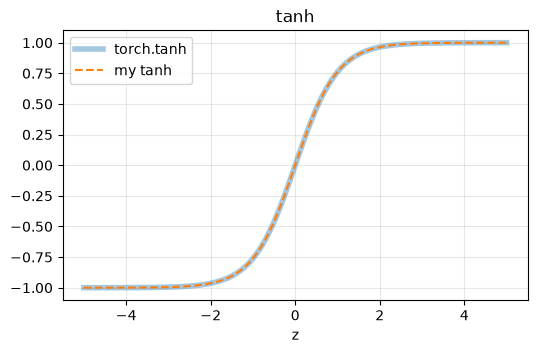

my tanh(100)      = nan
torch.tanh(100)   = 1.0
tanh_safe(100)    = 1.0
tanh_safe(-100)   = -1.0
max |tanh_safe - torch.tanh| on [-5, 5]: 1.1920928955078125e-07


In [75]:
# Exercise 6
def tanh(z):
    return (torch.exp(z) - torch.exp(-z)) / (torch.exp(z) + torch.exp(-z))

z = torch.linspace(-5, 5, 101)
print("max |my tanh - torch.tanh| on [-5, 5]:", (tanh(z) - torch.tanh(z)).abs().max().item())

plt.figure(figsize=(6, 3.5))
plt.plot(z, torch.tanh(z), label="torch.tanh", linewidth=4, alpha=0.4)
plt.plot(z, tanh(z), "--", label="my tanh")
plt.xlabel("z"); plt.legend(); plt.grid(alpha=0.3); plt.title("tanh"); plt.show()

# Optional: z = 100
z_big = torch.tensor([100.0])
print("my tanh(100)      =", tanh(z_big).item())          # exp(100) overflows in float32 -> inf / inf = nan
print("torch.tanh(100)   =", torch.tanh(z_big).item())

def tanh_safe(z):
    return 2 * torch.sigmoid(2 * z) - 1

print("tanh_safe(100)    =", tanh_safe(z_big).item())
print("tanh_safe(-100)   =", tanh_safe(-z_big).item())
print("max |tanh_safe - torch.tanh| on [-5, 5]:", (tanh_safe(z) - torch.tanh(z)).abs().max().item())


The direct `tanh` formula was implemented using `torch.exp` and compared with `torch.tanh` at 101 values from `-5` to `5`. The two curves nearly overlapped, with a maximum absolute difference of approximately `1.19 × 10⁻⁷`.

At `z=100`, `exp(100)` exceeds the range of `float32`, so the direct formula produces `inf / inf`, which returns `nan`. The sigmoid-based formula, `2 * sigmoid(2*z) - 1`, returned `1.0` at `z=100` and `-1.0` at `z=-100`.

-- Khmer --

ការ​​ impletment រូបមន្ត `tanh` ផ្ទាល់ដោយប្រើ `torch.exp` ហើយយកវាទៅប្រៀបធៀបជាមួយ `torch.tanh` លើតម្លៃ ១០១ នៅចន្លោះពី `-5` ដល់ `5`។ ធ្វើខ្សែកោងទាំងពីរមើលទៅស្ទើរតែត្រួតពីលើគ្នា ដោយមានគម្លាតខុសគ្នាធំបំផុតប្រហែលតែ `1.19 × 10⁻⁷`​​ ប៉ុណ្ណោះ។

នៅពេលដែល `z=100` តម្លៃ `exp(100)` ធំហួសកម្រិតដែល `float32` អាចដាក់បាន។ ដូច្នេះរូបមន្តផ្ទាល់អាចឈានដល់ការគណនា `inf / inf` ដែលផ្តល់លទ្ធផលជា `nan`។ ដោយឡែករូបមន្ត `2 * sigmoid(2*z) - 1` ផ្តល់លទ្ធផល `1.0` នៅពេលដែល `z=100` និង `-1.0` នៅពេលដែល `z=-100`។

### Exercise 7 · A multi-class problem: spirals
Create the 3-class spiral dataset of CS231n with the code below (300 points), turn it into tensors (`X` as `float32`, `y` as `long` of shape $(m,)$), and split it 80/20 with `random_state=42`.

Then:
- build a model capable of fitting the data; it outputs **3 logits** (one per class);
- use `nn.CrossEntropyLoss()` (softmax + cross-entropy, Lecture 2) and an optimizer (optional extension: `torch.optim.Adam`; you may have to try several learning rates);
- write a training and testing loop for the multi-class case (predicted class = `argmax` of the logits) and reach **more than 95% test accuracy**;
- plot the decision boundaries on the training and test sets with `plot_decision_boundary` (it handles several classes).

```python
# Code for creating a spiral dataset from CS231n
np.random.seed(42)
N = 100  # number of points per class
D = 2    # dimensionality
K = 3    # number of classes
X = np.zeros((N * K, D))           # data matrix (each row = single example)
y = np.zeros(N * K, dtype="uint8")  # class labels
for j in range(K):
    ix = range(N * j, N * (j + 1))
    r = np.linspace(0.0, 1, N)                                    # radius
    t = np.linspace(j * 4, (j + 1) * 4, N) + np.random.randn(N) * 0.2  # theta
    X[ix] = np.c_[r * np.sin(t), r * np.cos(t)]
    y[ix] = j
plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.Spectral)
plt.show()
```

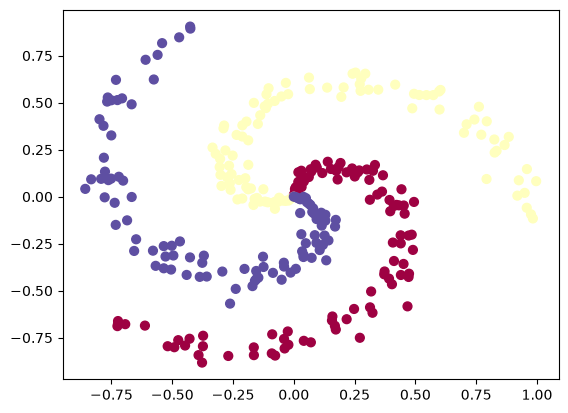

train: (240, 2) (240,) | test: (60, 2) (60,)
Epoch:     0 | Loss: 1.09549, Accuracy: 33.33% | Test loss: 1.03733, Test acc: 51.67%
Epoch:   100 | Loss: 0.03415, Accuracy: 99.17% | Test loss: 0.00728, Test acc: 100.00%
Epoch:   200 | Loss: 0.02122, Accuracy: 99.17% | Test loss: 0.00074, Test acc: 100.00%
Epoch:   300 | Loss: 0.01740, Accuracy: 99.17% | Test loss: 0.00014, Test acc: 100.00%
Epoch:   400 | Loss: 0.01586, Accuracy: 99.17% | Test loss: 0.00005, Test acc: 100.00%
Epoch:   500 | Loss: 0.01502, Accuracy: 99.17% | Test loss: 0.00002, Test acc: 100.00%
Epoch:   600 | Loss: 0.01465, Accuracy: 99.17% | Test loss: 0.00002, Test acc: 100.00%
Epoch:   700 | Loss: 0.01435, Accuracy: 99.17% | Test loss: 0.00003, Test acc: 100.00%
Epoch:   800 | Loss: 0.01421, Accuracy: 99.17% | Test loss: 0.00003, Test acc: 100.00%
Epoch:   900 | Loss: 0.01427, Accuracy: 99.17% | Test loss: 0.00002, Test acc: 100.00%

final: train accuracy 99.2% | test accuracy 100.0%


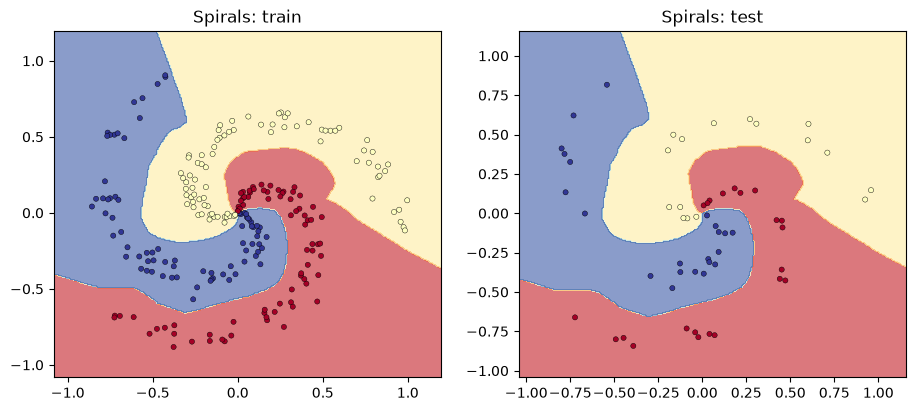

In [76]:
# Exercise 7: data
np.random.seed(42)
N = 100  # number of points per class
D = 2    # dimensionality
K = 3    # number of classes
X = np.zeros((N * K, D))           # data matrix (each row = single example)
y = np.zeros(N * K, dtype="uint8")  # class labels
for j in range(K):
    ix = range(N * j, N * (j + 1))
    r = np.linspace(0.0, 1, N)                                    # radius
    t = np.linspace(j * 4, (j + 1) * 4, N) + np.random.randn(N) * 0.2  # theta
    X[ix] = np.c_[r * np.sin(t), r * np.cos(t)]
    y[ix] = j
plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.Spectral)
plt.show()

spi_X = torch.tensor(X, dtype=torch.float32)
spi_y = torch.tensor(y, dtype=torch.long)                         # shape (m,), as CrossEntropyLoss expects
spi_Xtr, spi_Xte, spi_ytr, spi_yte = train_test_split(spi_X, spi_y, test_size=0.2, random_state=42)
print("train:", tuple(spi_Xtr.shape), tuple(spi_ytr.shape), "| test:", tuple(spi_Xte.shape), tuple(spi_yte.shape))

# model: 3 logits (one per class)
class SpiralModel(nn.Module):
    def __init__(self, hidden=64, p=0.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden), nn.ReLU(), nn.Dropout(p),
            nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(p),
            nn.Linear(hidden, 3))
    def forward(self, x):
        return self.net(x)

# loss, optimizer, training and testing loop
def train_and_test_multiclass(model, loss_fn, optimizer, X_train, y_train, X_test, y_test, epochs, print_every=None):
    X_train, y_train, X_test, y_test = X_train.to(device), y_train.to(device), X_test.to(device), y_test.to(device)
    for epoch in range(epochs):
        model.train()
        logits = model(X_train)
        loss = loss_fn(logits, y_train)
        acc = accuracy_fn(y_train, logits.argmax(dim=1))          # predicted class = argmax of the logits
        optimizer.zero_grad(); loss.backward(); optimizer.step()

        model.eval()
        with torch.inference_mode():
            test_logits = model(X_test)
            test_loss = loss_fn(test_logits, y_test)
            test_acc = accuracy_fn(y_test, test_logits.argmax(dim=1))
        if print_every and epoch % print_every == 0:
            print(f"Epoch: {epoch:5d} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%")
    return model

torch.manual_seed(42)
spiral_model = SpiralModel(hidden=64).to(device)
spiral_loss_fn = nn.CrossEntropyLoss()                            # softmax + cross-entropy
spiral_optimizer = torch.optim.Adam(spiral_model.parameters(), lr=0.01)
spiral_model = train_and_test_multiclass(spiral_model, spiral_loss_fn, spiral_optimizer,
                                         spi_Xtr, spi_ytr, spi_Xte, spi_yte, epochs=1000, print_every=100)
print(f"\nfinal: train accuracy {accuracy(spiral_model, spi_Xtr, spi_ytr):.1f}% | "
      f"test accuracy {accuracy(spiral_model, spi_Xte, spi_yte):.1f}%")

# decision boundaries
plt.figure(figsize=(11, 4.5))
plt.subplot(1, 2, 1); plt.title("Spirals: train")
plot_decision_boundary(spiral_model, spi_Xtr, spi_ytr)
plt.subplot(1, 2, 2); plt.title("Spirals: test")
plot_decision_boundary(spiral_model, spi_Xte, spi_yte)
plt.show()

The spiral dataset contains 300 points across three classes, split into 240 training points and 60 test points. `SpiralModel` outputs three logits per point, one for each class. It was trained with `CrossEntropyLoss` and Adam. The predicted class was selected using `argmax` over the three logits.

The final model achieved 99.2% training accuracy and 100% test accuracy, exceeding the required 95% threshold. Decision boundaries were plotted for both sets to show how the model separates the three classes.

-- Khmer --

សំណុំទិន្នន័យរាងគូទខ​្យងដែលមាន ៣០០ ចំណុច ចែកជាបីក្រុម។ ក្នុងនោះ ២៤០ ចំណុចត្រូវបានប្រើសម្រាប់បណ្តុះបណ្តាល(Training) និង ៦០ ចំណុចសម្រាប់ធ្វើតេស្ត(Test) ។ ចំពោះចំណុចនីមួយៗ `SpiralModel` បញ្ចេញ logit មួយសម្រាប់ក្រុមនីមួយៗ។ ការបណ្តុះបណ្តាលប្រើ `CrossEntropyLoss` និង Adam ហើយ `argmax` ជ្រើសតែក្រុមដែលមាន logit ខ្ពស់ជាងគេប៉ុណ្ណោះ។

សរុបជារួមបង្ហាញថា Modelយើងទាយត្រូវ ៩៩.២% លើសំណុំបណ្តុះបណ្តាល(Training) និង ១០០% លើសំណុំតេស្ត(Test) ដែលលើសលក្ខខណ្ឌ ៩៥%។ ហើយខ្សែបន្ទាត់បែងចែកត្រូវបានគូរលើសំណុំទាំងពីរ ដើម្បីបង្ហាញពីរបៀបដែលម៉ូដែលបែងចែកក្រុមទាំងបី។

### Exercise 8 · Regularization on the spirals (TP3)
Train a **much larger** spiral model (for example two hidden layers of 128 units) for long enough that it overfits: training accuracy near 100%, and a visible gap with the test accuracy. Then train the same model with
- **L2 regularization** (`weight_decay` on the weights only, as in Part 2.5), and
- **dropout** (`nn.Dropout`),

keeping everything else equal. Report the training and test accuracy of the three models in a small table, plot the three decision boundaries, and answer in a markdown cell: which model would you choose, and why? Which set should be used to choose `weight_decay` and the dropout rate in a real project?

model                       train acc   test acc  test loss
no regularization               98.3%      88.3%      0.999
L2 (weight_decay=1e-3)          88.8%      91.7%      0.317
dropout (p=0.4)                 91.2%      88.3%      0.296


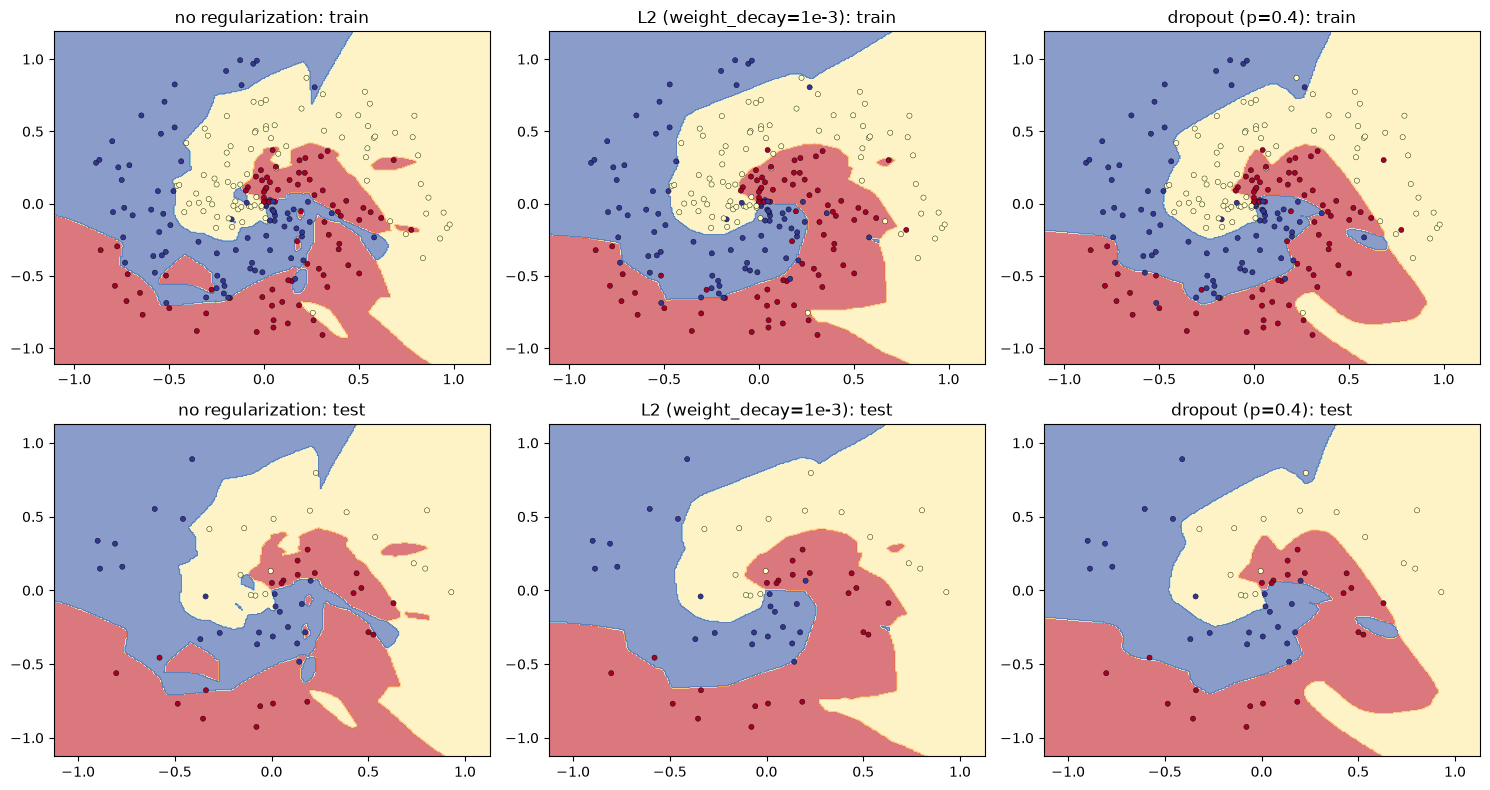

In [77]:
# Exercise 8
# NOTE: on the standard spirals (noise 0.2) even a huge network reaches 100% test accuracy, so there is no
# train/test gap to observe. To make overfitting visible, we regenerate the SAME spirals with a noisier angle
# (noise 0.7, everything else identical) and use that data for the three models below.
def make_spirals(noise, N=100, K=3, seed=42):
    np.random.seed(seed)
    X = np.zeros((N * K, 2)); y = np.zeros(N * K, dtype="uint8")
    for j in range(K):
        ix = range(N * j, N * (j + 1))
        r = np.linspace(0.0, 1, N)
        t = np.linspace(j * 4, (j + 1) * 4, N) + np.random.randn(N) * noise
        X[ix] = np.c_[r * np.sin(t), r * np.cos(t)]; y[ix] = j
    return torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.long)

noisy_X, noisy_y = make_spirals(noise=0.7)
nX_tr, nX_te, ny_tr, ny_te = train_test_split(noisy_X, noisy_y, test_size=0.2, random_state=42)

def train_big_spiral(p=0.0, weight_decay=0.0, epochs=3000, lr=0.005, seed=0):
    torch.manual_seed(seed)
    model = SpiralModel(hidden=128, p=p).to(device)                # two hidden layers of 128 units
    weights = [q for n, q in model.named_parameters() if n.endswith("weight")]
    biases = [q for n, q in model.named_parameters() if n.endswith("bias")]
    optimizer = torch.optim.Adam([{"params": weights, "weight_decay": weight_decay},   # L2 on the weights only
                                  {"params": biases, "weight_decay": 0.0}], lr=lr)
    return train_and_test_multiclass(model, nn.CrossEntropyLoss(), optimizer, nX_tr, ny_tr, nX_te, ny_te, epochs)

models_8 = {
    "no regularization": train_big_spiral(),
    "L2 (weight_decay=1e-3)": train_big_spiral(weight_decay=1e-3),
    "dropout (p=0.4)": train_big_spiral(p=0.4),
}

ce = nn.CrossEntropyLoss()
def test_loss(m):
    m.eval()
    with torch.inference_mode():
        return ce(m(nX_te.to(device)), ny_te.to(device)).item()

print(f"{'model':26s} {'train acc':>10s} {'test acc':>10s} {'test loss':>10s}")
for name, m in models_8.items():
    print(f"{name:26s} {accuracy(m, nX_tr, ny_tr):9.1f}% {accuracy(m, nX_te, ny_te):9.1f}% {test_loss(m):10.3f}")

plt.figure(figsize=(15, 8))
for k, (name, m) in enumerate(models_8.items()):
    plt.subplot(2, 3, k + 1); plt.title(f"{name}: train"); plot_decision_boundary(m, nX_tr, ny_tr)
    plt.subplot(2, 3, k + 4); plt.title(f"{name}: test");  plot_decision_boundary(m, nX_te, ny_te)
plt.tight_layout(); plt.show()


The spiral noise was increased from `0.2` to `0.7` to make overfitting easier to observe. Three configurations were compared using the same data split and model architecture, with 128 units in each of two hidden layers. All runs used the same initialization seed, Adam with a learning rate of `0.005`, and 3,000 epochs. Decision boundaries were plotted on the training and test sets for each configuration.


| Model / ម៉ូដែល | Train accuracy | Test accuracy | Test loss |
|---|---:|---:|---:|
| No regularization / គ្មាន regularization | 98.3% | 88.3% | 0.999 |
| L2 (`weight_decay=1e-3`, weights only) | 88.8% | **91.7%** | 0.317 |
| Dropout (`p=0.4`) | 91.2% | 88.3% | **0.296** |

**Conclusion**

The baseline showed signs of overfitting, with 98.3% training accuracy and 88.3% test accuracy. I would choose L2 for this comparison because it achieved the highest test accuracy, at 91.7%. Dropout had the lowest test loss. L2 classified only two more test points correctly than dropout, so the accuracy ranking is based on a small difference. In a real project, I would select `weight_decay` and the dropout rate on a separate validation set and reserve the test set for final evaluation.

**សេចក្តីសន្និដ្ឋាន**

Model ដែលមិនប្រើ regularization បង្ហាញសញ្ញានៃ overfitting ដោយទាយត្រូវ ៩៨.៣% លើសំណុំបណ្តុះបណ្តាល(Training) និង ៨៨.៣% លើសំណុំតេស្ត(Test)។ សម្រាប់ការប្រៀបធៀបនេះ ខ្ញុំជ្រើសយក L2 ព្រោះវាទទួលបាន test accuracy ខ្ពស់ជាងគេ គឺ ៩១.៧%។ ចំណែក Dropout មាន test loss ទាបជាងគេ។ ក្នុងចំណោមចំណុចតេស្តទាំង ៦០ Model L2 ទាយត្រូវច្រើនជាង Dropout តែពីរចំណុចប៉ុណ្ណោះ ដូច្នេះចំណាត់ថ្នាក់តាម accuracy ផ្អែកលើគម្លាតតិចតួច។ ក្នុងគម្រោងជាក់ស្តែង ខ្ញុំនឹងប្រើសំណុំ validation ដាច់ដោយឡែកសម្រាប់ជ្រើស `weight_decay` និង dropout rate ហើយទុកសំណុំតេស្តសម្រាប់ការវាយតម្លៃចុងក្រោយ។